In [1]:
#Data Manipulation specific
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
from scipy import signal
from netCDF4 import Dataset
from osgeo import gdal
#Visualisation specific
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline
import scipy.io
import cdsapi
import xarray as xr
from urllib.request import urlopen# start the client
import requests
import certifi
import urllib3
import cdsapi
from shapely.geometry import mapping
import geopandas as gpd
import rasterio
import rasterio.mask
import rioxarray

c:\Users\Oubaha.ANAS\Anaconda3\lib\site-packages\scipy\__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.25.0 is required for this version of SciPy (detected version 1.26.3
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [ ]:
%pip install C:/Users/Oubaha.ANAS/GDAL-3.4.3-cp39-cp39-win_amd64.whl

In [26]:

r = requests.get("http://google.com")       
print(r.status_code)

200


In [19]:

http = urllib3.PoolManager(
    cert_reqs='CERT_REQUIRED',
    ca_certs=certifi.where()
)

In [20]:
cds = cdsapi.Client()# dataset you want to read

In [31]:
url = 'https://cds.climate.copernicus.eu/api/v2'
key = '183169:0ba5f9d6-870e-4e73-98a2-120ef76c0683'

## hada dkhal l youtube rah ghatl9a kifach dir had lfichier f  lhome dyalk
with open('C:/Users/ASchynO/.cdsapirc', 'w') as f:
    f.write('\n'.join([url, key]))

with open('C:/Users/ASchynO/.cdsapirc') as f:
    print(f.read())

https://cds.climate.copernicus.eu/api/v2
183169:0ba5f9d6-870e-4e73-98a2-120ef76c0683


In [ ]:
## ana 9ssamt dakchi l 2 ans 7It requiest makadozch ila drt ktar

In [ ]:
c = cdsapi.Client()

c.retrieve(
    'reanalysis-era5-single-levels-monthly-means',
    {
        'format': 'netcdf',
        'product_type': 'monthly_averaged_reanalysis_by_hour_of_day',
        'variable': '2m_temperature',
        'year': [
            '1983', '1984', '1985',
            '1986', '1987', '1988',
            '1989', '1990', '1991',
            '1992', '1993', '1994',
            '1995', '1996', '1997',
            '1998', '1999', '2000',
            '2001', '2002', '2003',
            '2004', '2005', '2006',
            '2007', '2008', '2009',
            '2010', '2011', '2012',
            '2013', '2014', '2015',
            '2016', '2017', '2018',
            '2019', '2020', '2021',
            '2022',
        ],
        'month': [
            '01', '02', '03',
            '04', '05', '06',
            '07', '08', '09',
            '10', '11', '12',
        ],
        'time': [
            '04:00', '05:00', '06:00',
        ],
        'area': [
            37, -18, 20.25,
            0,
        ],
    },
    'download.nc')

In [9]:
#xarry bach n7ol les fichier
t= xr.open_dataset('D:\PhD\Datasets\ERA5\ERA5.nc')
#t_2023 = xr.open_dataset('D:\PhD\Datasets\ERA5\data_1.nc')
p = xr.open_dataset('D:\PhD\Datasets\PERSIANN-CDR\CDR.nc')

In [34]:
p

<xarray.Dataset>
Dimensions:   (datetime: 476, lon: 73, lat: 69)
Coordinates:
  * datetime  (datetime) datetime64[ns] 1983-01-01 1983-02-01 ... 2022-08-01
  * lon       (lon) float32 -17.75 -17.5 -17.25 -17.0 ... -0.5 -0.25 0.0 0.25
  * lat       (lat) float32 37.5 37.25 37.0 36.75 36.5 ... 21.25 21.0 20.75 20.5
Data variables:
    crs       int32 -2147483647
    precip    (datetime, lat, lon) float32 ...
Attributes:
    Conventions:  CF-1.6

In [7]:
i = xr.Dataset(
    {
        "precipitation": (( "time", "lat", "lon"), p["precip"].to_numpy(), {"units": "mm"}),
    },
    coords={"time": p["precip"]["datetime"].to_numpy(), "lat": p["precip"]["lat"].to_numpy(), "lon": p["precip"]["lon"].to_numpy()},
)
i

<xarray.Dataset>
Dimensions:        (time: 476, lat: 69, lon: 73)
Coordinates:
  * time           (time) datetime64[ns] 1983-01-01 1983-02-01 ... 2022-08-01
  * lat            (lat) float32 37.5 37.25 37.0 36.75 ... 21.25 21.0 20.75 20.5
  * lon            (lon) float32 -17.75 -17.5 -17.25 -17.0 ... -0.25 0.0 0.25
Data variables:
    precipitation  (time, lat, lon) float32 49.71 46.5 40.85 ... 43.86 45.7

In [8]:
i.to_netcdf('D:\PhD\Datasets\PERSIANN-CDR\CDRm.nc')

In [4]:
t['t2m'] = (t['t2m'] -273.15)

In [10]:
p = p.drop_vars('crs')

In [6]:
pdt = t.to_dataframe(['time', 'latitude', 'longitude'])
pdt

t2m
time       latitude longitude           
1983-01-01 37.00    -18.00     15.213196
                    -17.75     15.195984
                    -17.50     15.193909
                    -17.25     15.205627
                    -17.00     15.219391
...                                  ...
2022-12-01 20.25    -1.00      23.013458
                    -0.75      23.073395
                    -0.50      22.936951
                    -0.25      23.025146
                     0.00      22.892151

[2382720 rows x 1 columns]

In [11]:
pdp = p.to_dataframe(['datetime', 'lat', 'lon'])
pdp

precip
datetime   lat  lon              
1983-01-01 37.5 -17.75  49.714588
                -17.50  46.504448
                -17.25  40.851837
                -17.00  37.140987
                -16.75  41.715736
...                           ...
2022-08-01 20.5 -0.75   38.178108
                -0.50   38.342121
                -0.25   35.542309
                 0.00   43.863758
                 0.25   45.698128

[2397612 rows x 1 columns]

In [8]:
result = pd.concat([pdp, pdt], axis=1, join='inner')

In [9]:
result
#(37.0, 20.5, -17.75, 0) -> (latxlon)=(67x72) (total of 4824 pixel) lat x 67 + lon

precip        t2m
1983-01-01 37.0 -17.75  45.372795  15.195984
                -17.50  41.519978  15.193909
                -17.25  38.298519  15.205627
                -17.00  33.130142  15.219391
                -16.75  33.649406  15.219391
...                           ...        ...
2022-08-01 20.5 -1.00   33.327618  35.436371
                -0.75   38.178108  35.424652
                -0.50   38.342121  35.448090
                -0.25   35.542309  35.250977
                 0.00   43.863758  34.801666

[2296224 rows x 2 columns]

In [28]:
#print(type(pdp.index.get_level_values("datetime")))
dates = pdt.index.get_level_values("time").to_numpy()
dates = list(dict.fromkeys(dates))
dates = dates[ : -4]
dates

[numpy.datetime64('1983-01-01T00:00:00.000000000'),
 numpy.datetime64('1983-02-01T00:00:00.000000000'),
 numpy.datetime64('1983-03-01T00:00:00.000000000'),
 numpy.datetime64('1983-04-01T00:00:00.000000000'),
 numpy.datetime64('1983-05-01T00:00:00.000000000'),
 numpy.datetime64('1983-06-01T00:00:00.000000000'),
 numpy.datetime64('1983-07-01T00:00:00.000000000'),
 numpy.datetime64('1983-08-01T00:00:00.000000000'),
 numpy.datetime64('1983-09-01T00:00:00.000000000'),
 numpy.datetime64('1983-10-01T00:00:00.000000000'),
 numpy.datetime64('1983-11-01T00:00:00.000000000'),
 numpy.datetime64('1983-12-01T00:00:00.000000000'),
 numpy.datetime64('1984-01-01T00:00:00.000000000'),
 numpy.datetime64('1984-02-01T00:00:00.000000000'),
 numpy.datetime64('1984-03-01T00:00:00.000000000'),
 numpy.datetime64('1984-04-01T00:00:00.000000000'),
 numpy.datetime64('1984-05-01T00:00:00.000000000'),
 numpy.datetime64('1984-06-01T00:00:00.000000000'),
 numpy.datetime64('1984-07-01T00:00:00.000000000'),
 numpy.datet

In [40]:
lisp = [result.loc[d, 'precip'].to_numpy() for d in dates]
lisp

C:\Users\ASchynO\AppData\Local\Temp\ipykernel_5072\3251496760.py:1: PerformanceWarning: indexing past lexsort depth may impact performance.
  lisp = [result.loc[d, 'precip'].to_numpy() for d in dates]


[array([45.372795, 41.519978, 38.29852 , ...,  0.      ,  0.      ,
         0.      ], dtype=float32),
 array([54.538227, 44.981575, 43.72963 , ...,  0.      ,  0.      ,
         0.      ], dtype=float32),
 array([43.373627  , 48.152634  , 47.04381   , ...,  0.2093873 ,
         0.24659859,  0.38913375], dtype=float32),
 array([55.761684, 54.91359 , 69.15198 , ...,  0.      ,  0.      ,
         0.      ], dtype=float32),
 array([35.753826, 41.820335, 36.096573, ...,  0.      ,  0.      ,
         0.      ], dtype=float32),
 array([38.01062 , 27.24785 , 34.22872 , ..., 25.857048, 23.63307 ,
        36.78558 ], dtype=float32),
 array([2.7644217, 9.811575 , 2.798529 , ..., 1.102965 , 1.1923927,
        1.1365387], dtype=float32),
 array([ 4.893239, 19.280413,  9.622746, ..., 36.6562  , 47.96356 ,
        66.382996], dtype=float32),
 array([23.73264 , 27.05186 , 25.047937, ...,  0.      ,  0.      ,
         0.      ], dtype=float32),
 array([66.46548   , 78.5107    , 74.35267   , ..., 

In [41]:
stack = np.dstack(lisp)
stack

array([[[45.372795  , 54.538227  , 43.373627  , ..., 11.451672  ,
          3.3358448 ,  4.3026104 ],
        [41.519978  , 44.981575  , 48.152634  , ..., 14.168227  ,
          4.0258594 ,  6.8806257 ],
        [38.29852   , 43.72963   , 47.04381   , ..., 15.077348  ,
          1.7096778 ,  3.246977  ],
        ...,
        [ 0.        ,  0.        ,  0.2093873 , ...,  5.6683764 ,
         15.721779  , 38.34212   ],
        [ 0.        ,  0.        ,  0.24659859, ...,  6.6942186 ,
         15.940118  , 35.54231   ],
        [ 0.        ,  0.        ,  0.38913375, ...,  7.6916842 ,
         11.441097  , 43.863758  ]]], dtype=float32)

In [42]:
def dataframe(p):

    df = pd.DataFrame({'Dates': dates, 'precip': stack[0][p]})
    df.set_index("Dates", inplace = True)
    return df

In [43]:
dataframe(4823)

,precip
Dates,
1983-01-01,0.000000
1983-02-01,0.000000
1983-03-01,0.389134
1983-04-01,0.000000
1983-05-01,0.000000
...,...
2022-04-01,0.027247
2022-05-01,1.757484
2022-06-01,7.691684


In [44]:
frames = [dataframe(p) for p in range(0, 4824)]

In [45]:
frames

[               precip
 Dates                
 1983-01-01  45.372795
 1983-02-01  54.538227
 1983-03-01  43.373627
 1983-04-01  55.761684
 1983-05-01  35.753826
 ...               ...
 2022-04-01  29.962677
 2022-05-01  47.754379
 2022-06-01  11.451672
 2022-07-01   3.335845
 2022-08-01   4.302610
 
 [476 rows x 1 columns],
                precip
 Dates                
 1983-01-01  41.519978
 1983-02-01  44.981575
 1983-03-01  48.152634
 1983-04-01  54.913589
 1983-05-01  41.820335
 ...               ...
 2022-04-01  30.328920
 2022-05-01  36.569641
 2022-06-01  14.168227
 2022-07-01   4.025859
 2022-08-01   6.880626
 
 [476 rows x 1 columns],
                precip
 Dates                
 1983-01-01  38.298519
 1983-02-01  43.729630
 1983-03-01  47.043812
 1983-04-01  69.151978
 1983-05-01  36.096573
 ...               ...
 2022-04-01  33.085712
 2022-05-01  33.544525
 2022-06-01  15.077348
 2022-07-01   1.709678
 2022-08-01   3.246977
 
 [476 rows x 1 columns],
                precip

In [46]:
df = pd.concat(frames,axis=1)

In [47]:
df

,precip,precip,precip,precip,precip,precip,precip,precip,precip,precip,...,precip,precip,precip,precip,precip,precip,precip,precip,precip,precip
Dates,,,,,,,,,,,,,,,,,,,,,
1983-01-01,45.372795,41.519978,38.298519,33.130142,33.649406,43.004398,37.958542,46.379086,40.360332,42.310848,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1983-02-01,54.538227,44.981575,43.729630,38.954319,39.524376,43.692974,46.819496,46.842701,39.810715,31.996815,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1983-03-01,43.373627,48.152634,47.043812,59.528854,51.707195,43.105110,41.883816,40.159248,38.529602,38.974907,...,0.510164,0.706140,0.417943,0.000000,0.000000,0.220665,0.197361,0.209387,0.246599,0.389134
1983-04-01,55.761684,54.913589,69.151978,59.632690,64.048241,53.445171,56.921368,59.128273,54.414688,62.275459,...,0.267766,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1983-05-01,35.753826,41.820335,36.096573,33.503025,39.073952,33.861347,29.803953,41.040310,27.788918,30.194946,...,0.000000,0.000000,0.180426,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-04-01,29.962677,30.328920,33.085712,31.671246,31.842527,32.053570,29.827665,23.975008,35.034683,24.740078,...,0.051412,0.032757,0.027820,0.015006,0.018991,0.009296,0.002679,0.006830,0.019800,0.027247
2022-05-01,47.754379,36.569641,33.544525,31.114515,35.936783,34.583271,34.617691,30.771700,33.049126,33.072239,...,0.849882,1.175693,0.943517,0.919590,0.857849,1.069258,1.381420,1.566892,1.263503,1.757484
2022-06-01,11.451672,14.168227,15.077348,9.552426,9.393827,8.527346,7.471623,9.089783,5.421932,7.362140,...,7.296117,6.383903,5.676613,6.132770,6.896019,6.472976,5.797501,5.668376,6.694219,7.691684


In [48]:
df.columns = [str(i) for i in range(4824)]
df

,0,1,2,3,4,5,6,7,8,9,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
Dates,,,,,,,,,,,,,,,,,,,,,
1983-01-01,45.372795,41.519978,38.298519,33.130142,33.649406,43.004398,37.958542,46.379086,40.360332,42.310848,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1983-02-01,54.538227,44.981575,43.729630,38.954319,39.524376,43.692974,46.819496,46.842701,39.810715,31.996815,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1983-03-01,43.373627,48.152634,47.043812,59.528854,51.707195,43.105110,41.883816,40.159248,38.529602,38.974907,...,0.510164,0.706140,0.417943,0.000000,0.000000,0.220665,0.197361,0.209387,0.246599,0.389134
1983-04-01,55.761684,54.913589,69.151978,59.632690,64.048241,53.445171,56.921368,59.128273,54.414688,62.275459,...,0.267766,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1983-05-01,35.753826,41.820335,36.096573,33.503025,39.073952,33.861347,29.803953,41.040310,27.788918,30.194946,...,0.000000,0.000000,0.180426,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-04-01,29.962677,30.328920,33.085712,31.671246,31.842527,32.053570,29.827665,23.975008,35.034683,24.740078,...,0.051412,0.032757,0.027820,0.015006,0.018991,0.009296,0.002679,0.006830,0.019800,0.027247
2022-05-01,47.754379,36.569641,33.544525,31.114515,35.936783,34.583271,34.617691,30.771700,33.049126,33.072239,...,0.849882,1.175693,0.943517,0.919590,0.857849,1.069258,1.381420,1.566892,1.263503,1.757484
2022-06-01,11.451672,14.168227,15.077348,9.552426,9.393827,8.527346,7.471623,9.089783,5.421932,7.362140,...,7.296117,6.383903,5.676613,6.132770,6.896019,6.472976,5.797501,5.668376,6.694219,7.691684


In [49]:
df.to_csv("precip_pixels.csv")

**CRU data**

In [3]:
cru = xr.open_dataset('D:\PhD\Datasets\CRU\cruts406.nc')

c:\Users\ASchynO\anaconda3\lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated
  "class": algorithms.Blowfish,
c:\Users\ASchynO\anaconda3\lib\site-packages\xarray\backends\plugins.py:65: RuntimeWarning: Engine 'gini' loading failed:
No module named 'matplotlib.axes'
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)
c:\Users\ASchynO\anaconda3\lib\site-packages\xarray\backends\plugins.py:65: RuntimeWarning: Engine 'rasterio' loading failed:
DLL load failed while importing _base: The specified module could not be found.
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


In [4]:
cru

<xarray.Dataset>
Dimensions:  (lon: 36, lat: 33, time: 446)
Coordinates:
  * lon      (lon) float32 -17.75 -17.25 -16.75 -16.25 ... -1.25 -0.75 -0.25
  * lat      (lat) float32 20.75 21.25 21.75 22.25 ... 35.25 35.75 36.25 36.75
  * time     (time) datetime64[ns] 1983-01-16 1983-02-15 ... 2020-02-15
Data variables:
    pre      (time, lat, lon) float32 ...
    stn      (time, lat, lon) float64 ...
Attributes:
    Conventions:  CF-1.4
    title:        CRU TS4.06 Precipitation
    institution:  Data held at British Atmospheric Data Centre, RAL, UK.
    source:       Run ID = 2204291347. Data generated from:pre.2204291209.dtb
    history:      Fri 29 Apr 16:08:23 BST 2022 : User f098 : Program makegrid...
    references:   Information on the data is available at http://badc.nerc.ac...
    comment:      Access to these data is available to any registered CEDA user.
    contact:      support@ceda.ac.uk

In [5]:
cru = cru.drop_vars('stn')

In [12]:
pdp

precip
datetime   lat  lon              
1983-01-01 37.5 -17.75  49.714588
                -17.50  46.504448
                -17.25  40.851837
                -17.00  37.140987
                -16.75  41.715736
...                           ...
2022-08-01 20.5 -0.75   38.178108
                -0.50   38.342121
                -0.25   35.542309
                 0.00   43.863758
                 0.25   45.698128

[2397612 rows x 1 columns]

In [6]:
pdu = cru.to_dataframe(['time', 'lat', 'lon'])
#pdu = pdu.head(1188) #130680 = 1188x110
pdu

pre
time       lat   lon        
1983-01-16 20.75 -17.75  NaN
                 -17.25  8.8
                 -16.75  6.3
                 -16.25  5.0
                 -15.75  3.8
...                      ...
2020-02-15 36.75 -2.25   0.8
                 -1.75   0.5
                 -1.25   1.5
                 -0.75   NaN
                 -0.25   NaN

[529848 rows x 1 columns]

In [7]:
import datetime as dt
index = pdu.index
index = pdu.index.tolist()
newindex = []
for i in index:
    o = dt.datetime.strftime(i[0], '%Y-%m-%d')
    newindex.append((o[:-2] + "01", i[1], i[2]))

pdu.index = pd.MultiIndex.from_tuples(newindex, names = ['datetime', 'lat', 'lon'])
dates = pdu.index.get_level_values("datetime").to_numpy()
dates = list(dict.fromkeys(dates))

In [8]:
pdu

pre
datetime   lat   lon        
1983-01-01 20.75 -17.75  NaN
                 -17.25  8.8
                 -16.75  6.3
                 -16.25  5.0
                 -15.75  3.8
...                      ...
2020-02-01 36.75 -2.25   0.8
                 -1.75   0.5
                 -1.25   1.5
                 -0.75   NaN
                 -0.25   NaN

[529848 rows x 1 columns]

In [15]:
#print(type(pdp.index.get_level_values("datetime")))
dates = pdu.index.get_level_values("datetime").to_numpy()
dates = list(dict.fromkeys(dates))
dates

['1983-01-01',
 '1983-02-01',
 '1983-03-01',
 '1983-04-01',
 '1983-05-01',
 '1983-06-01',
 '1983-07-01',
 '1983-08-01',
 '1983-09-01',
 '1983-10-01',
 '1983-11-01',
 '1983-12-01',
 '1984-01-01',
 '1984-02-01',
 '1984-03-01',
 '1984-04-01',
 '1984-05-01',
 '1984-06-01',
 '1984-07-01',
 '1984-08-01',
 '1984-09-01',
 '1984-10-01',
 '1984-11-01',
 '1984-12-01',
 '1985-01-01',
 '1985-02-01',
 '1985-03-01',
 '1985-04-01',
 '1985-05-01',
 '1985-06-01',
 '1985-07-01',
 '1985-08-01',
 '1985-09-01',
 '1985-10-01',
 '1985-11-01',
 '1985-12-01',
 '1986-01-01',
 '1986-02-01',
 '1986-03-01',
 '1986-04-01',
 '1986-05-01',
 '1986-06-01',
 '1986-07-01',
 '1986-08-01',
 '1986-09-01',
 '1986-10-01',
 '1986-11-01',
 '1986-12-01',
 '1987-01-01',
 '1987-02-01',
 '1987-03-01',
 '1987-04-01',
 '1987-05-01',
 '1987-06-01',
 '1987-07-01',
 '1987-08-01',
 '1987-09-01',
 '1987-10-01',
 '1987-11-01',
 '1987-12-01',
 '1988-01-01',
 '1988-02-01',
 '1988-03-01',
 '1988-04-01',
 '1988-05-01',
 '1988-06-01',
 '1988-07-

In [16]:
lisp = [pdu.loc[d, 'pre'].to_numpy() for d in dates]
lisp

[array([nan, 8.8, 6.3, ..., 1.2, nan, nan], dtype=float32),
 array([ nan,  0. ,  0. , ..., 45.4,  nan,  nan], dtype=float32),
 array([nan, 0. , 0.1, ..., 7. , nan, nan], dtype=float32),
 array([nan, 0. , 0.1, ..., 5.6, nan, nan], dtype=float32),
 array([nan, 0. , 0. , ..., 3.5, nan, nan], dtype=float32),
 array([nan, 0. , 0. , ..., 3.8, nan, nan], dtype=float32),
 array([nan, 0. , 0. , ..., 1.2, nan, nan], dtype=float32),
 array([nan, 0.1, 0.5, ..., 4.5, nan, nan], dtype=float32),
 array([nan, 1.4, 2.8, ..., 0.3, nan, nan], dtype=float32),
 array([nan, 0. , 0. , ..., 9.3, nan, nan], dtype=float32),
 array([ nan,  0. ,  0. , ..., 74.6,  nan,  nan], dtype=float32),
 array([      nan,  0.      ,  0.      , ..., 39.100002,       nan,
              nan], dtype=float32),
 array([      nan,  0.      ,  0.      , ..., 23.300001,       nan,
              nan], dtype=float32),
 array([      nan,  0.      ,  0.      , ..., 28.800001,       nan,
              nan], dtype=float32),
 array([ nan,  0

In [17]:
stack = np.dstack(lisp)
stack

array([[[ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ 8.8,  0. ,  0. , ...,  0. ,  0. ,  0. ],
        [ 6.3,  0. ,  0.1, ...,  0. ,  0. ,  0. ],
        ...,
        [ 1.2, 45.4,  7. , ..., 58.5, 60.4,  1.5],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan]]], dtype=float32)

In [18]:
def dataframe(p):

    df = pd.DataFrame({'Dates': dates, 'precip': stack[0][p]})
    df.set_index("Dates", inplace = True)
    return df

In [20]:
dataframe(1187)

,precip
Dates,
1983-01-01,NaN
1983-02-01,NaN
1983-03-01,NaN
1983-04-01,NaN
1983-05-01,NaN
...,...
2019-10-01,NaN
2019-11-01,NaN
2019-12-01,NaN


In [21]:
frames = [dataframe(p) for p in range(0, 1188)]

In [22]:
frames

[            precip
 Dates             
 1983-01-01     NaN
 1983-02-01     NaN
 1983-03-01     NaN
 1983-04-01     NaN
 1983-05-01     NaN
 ...            ...
 2019-10-01     NaN
 2019-11-01     NaN
 2019-12-01     NaN
 2020-01-01     NaN
 2020-02-01     NaN
 
 [446 rows x 1 columns],
             precip
 Dates             
 1983-01-01     8.8
 1983-02-01     0.0
 1983-03-01     0.0
 1983-04-01     0.0
 1983-05-01     0.0
 ...            ...
 2019-10-01     3.9
 2019-11-01     1.6
 2019-12-01     0.0
 2020-01-01     0.0
 2020-02-01     0.0
 
 [446 rows x 1 columns],
             precip
 Dates             
 1983-01-01     6.3
 1983-02-01     0.0
 1983-03-01     0.1
 1983-04-01     0.1
 1983-05-01     0.0
 ...            ...
 2019-10-01     5.0
 2019-11-01     1.6
 2019-12-01     0.0
 2020-01-01     0.0
 2020-02-01     0.0
 
 [446 rows x 1 columns],
             precip
 Dates             
 1983-01-01     5.0
 1983-02-01     0.0
 1983-03-01     0.2
 1983-04-01     0.2
 1983-05-01     0.0

In [23]:
df = pd.concat(frames,axis=1)

In [24]:
df

,precip,precip,precip,precip,precip,precip,precip,precip,precip,precip,...,precip,precip,precip,precip,precip,precip,precip,precip,precip,precip
Dates,,,,,,,,,,,,,,,,,,,,,
1983-01-01,NaN,8.8,6.3,5.0,3.8,3.5,2.8,1.5,0.6,0.0,...,0.100000,0.100000,0.200000,0.300000,0.700000,0.500000,0.600000,1.200000,NaN,NaN
1983-02-01,NaN,0.0,0.0,0.0,0.1,0.2,0.2,0.2,0.9,1.3,...,42.200001,41.000000,42.299999,37.200001,30.900000,27.600000,23.100000,45.400002,NaN,NaN
1983-03-01,NaN,0.0,0.1,0.2,0.4,1.0,1.6,1.4,1.0,1.4,...,28.800001,25.600000,20.900000,18.900000,15.300000,10.800000,10.200000,7.000000,NaN,NaN
1983-04-01,NaN,0.0,0.1,0.2,0.6,2.0,3.4,2.9,1.6,2.6,...,54.400002,41.000000,26.600000,25.100000,17.100000,10.600000,7.100000,5.600000,NaN,NaN
1983-05-01,NaN,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,...,10.300000,9.200000,7.500000,7.700000,6.400000,4.500000,4.000000,3.500000,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-10-01,NaN,3.9,5.0,6.1,7.5,10.0,11.0,9.8,7.3,6.8,...,30.700001,36.100002,39.000000,37.200001,31.100000,31.500000,34.700001,46.299999,NaN,NaN
2019-11-01,NaN,1.6,1.6,1.6,1.8,2.6,3.3,3.0,2.2,2.7,...,90.400002,74.800003,63.700001,53.299999,39.799999,29.600000,29.100000,43.000000,NaN,NaN
2019-12-01,NaN,0.0,0.0,0.0,0.1,0.5,1.1,1.5,1.4,1.7,...,99.200005,80.599998,61.900002,54.500000,52.500000,38.200001,33.700001,58.500000,NaN,NaN


In [25]:
df.columns = [str(i) for i in range(1188)]
df

,0,1,2,3,4,5,6,7,8,9,...,1178,1179,1180,1181,1182,1183,1184,1185,1186,1187
Dates,,,,,,,,,,,,,,,,,,,,,
1983-01-01,NaN,8.8,6.3,5.0,3.8,3.5,2.8,1.5,0.6,0.0,...,0.100000,0.100000,0.200000,0.300000,0.700000,0.500000,0.600000,1.200000,NaN,NaN
1983-02-01,NaN,0.0,0.0,0.0,0.1,0.2,0.2,0.2,0.9,1.3,...,42.200001,41.000000,42.299999,37.200001,30.900000,27.600000,23.100000,45.400002,NaN,NaN
1983-03-01,NaN,0.0,0.1,0.2,0.4,1.0,1.6,1.4,1.0,1.4,...,28.800001,25.600000,20.900000,18.900000,15.300000,10.800000,10.200000,7.000000,NaN,NaN
1983-04-01,NaN,0.0,0.1,0.2,0.6,2.0,3.4,2.9,1.6,2.6,...,54.400002,41.000000,26.600000,25.100000,17.100000,10.600000,7.100000,5.600000,NaN,NaN
1983-05-01,NaN,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,...,10.300000,9.200000,7.500000,7.700000,6.400000,4.500000,4.000000,3.500000,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-10-01,NaN,3.9,5.0,6.1,7.5,10.0,11.0,9.8,7.3,6.8,...,30.700001,36.100002,39.000000,37.200001,31.100000,31.500000,34.700001,46.299999,NaN,NaN
2019-11-01,NaN,1.6,1.6,1.6,1.8,2.6,3.3,3.0,2.2,2.7,...,90.400002,74.800003,63.700001,53.299999,39.799999,29.600000,29.100000,43.000000,NaN,NaN
2019-12-01,NaN,0.0,0.0,0.0,0.1,0.5,1.1,1.5,1.4,1.7,...,99.200005,80.599998,61.900002,54.500000,52.500000,38.200001,33.700001,58.500000,NaN,NaN


In [26]:
df.to_csv("precip_cru.csv")

In [123]:
lt = [0, 0, 1, 1, 2, 2, 3, 3, 4, 4, 5, 5, 6, 6, 7, 7, 8, 8, 9, 9, 10, 10, 11, 11, 12, 12, 13 ,13, 14, 14, 15, 15, 16, 16, 17, 17, 18, 18, 19, 19]
#out = [x for pair in zip(lt,lt) for x in pair]
newl = []
for i in range(4): #number date
    inter = []
    for j in range(5): #number of lat in each date
        inter += lt[4*j + 20*i: 4*j + 20*i + 4] * 2 #10 is number of lon in each date, 4 is nymber of lat
    newl += [inter]

In [211]:
out = [x for pair in zip(pdu['pre'].to_numpy(),pdu['pre'].to_numpy()) for x in pair]
newl = []
for i in range(1):
    inter = []
    for j in range(68):
        inter += out[67*j + 72*i: 67*j + 72*i + 67] * 2
    newl += [inter]

In [203]:
len(out)

2376

In [216]:
newl[0]

[nan,
 nan,
 8.8,
 8.8,
 6.3,
 6.3,
 5.0,
 5.0,
 3.8,
 3.8,
 3.5,
 3.5,
 2.8,
 2.8,
 1.5,
 1.5,
 0.6,
 0.6,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.1,
 0.1,
 0.2,
 0.2,
 0.4,
 0.4,
 0.4,
 0.4,
 0.4,
 0.4,
 0.4,
 0.4,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.4,
 0.4,
 0.3,
 0.3,
 0.2,
 nan,
 nan,
 8.8,
 8.8,
 6.3,
 6.3,
 5.0,
 5.0,
 3.8,
 3.8,
 3.5,
 3.5,
 2.8,
 2.8,
 1.5,
 1.5,
 0.6,
 0.6,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.1,
 0.1,
 0.2,
 0.2,
 0.4,
 0.4,
 0.4,
 0.4,
 0.4,
 0.4,
 0.4,
 0.4,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.5,
 0.4,
 0.4,
 0.3,
 0.3,
 0.2,
 0.2,
 0.1,
 0.1,
 0.0,
 0.0,
 nan,
 nan,
 11.2,
 11.2,
 9.5,
 9.5,
 8.5,
 8.5,
 6.6,
 6.6,
 4.5,
 4.5,
 3.2,
 3.2,
 1.7,
 1.7,
 1.0,
 1.0,
 0.2,
 0.2,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.1,
 0

In [226]:
final = pd.DataFrame(pdu['pre'].to_numpy())
final

,0
0,NaN
1,8.8
2,6.3
3,5.0
4,3.8
...,...
1183,0.5
1184,0.6
1185,1.2
1186,NaN


In [227]:
final.to_csv("pdu.csv")

In [221]:
final.loc[len(final)] = newl
final

ValueError: cannot set a row with mismatched columns

In [192]:
final.insert(0, 'Dates', ['1984-02-01', '1984-05-01', '1984-06-01', '1990-02-01', '1992-02-01'])
final

ValueError: Length of values (5) does not match length of index (2)

In [40]:
p = pdu['pre'].to_numpy()
com = pd.DataFrame({'Dates': dates})
inter = pd.DataFrame()
for i in range(3): #111
    for j in range(3): #34
        for k in range(3):
            inter[str(j*k + k)] = p[j*k + k]
            inter[str(j*k + k+1)] = p[j*k + k]
        com = pd.concat([com, inter], axis=1, join='outer')
        

In [41]:
com

,Dates,0,1,2,3,0,1,2,3,4,...,6,7,0,1,2,3,4,5,6,7
0,1983-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1983-02-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1983-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1983-04-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1983-05-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,1991-10-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
106,1991-11-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
107,1991-12-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
108,1992-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
import datetime as dt
copy = pd.DataFrame({"pre": pdu['pre']})
index = pdu.index
index = pdu.index.tolist()
newindex = []
for i in index:
    o = dt.datetime.strftime(i[0], '%Y-%m-%d')
    newindex.append((o[:-2] + "01", str(i[1]+0.25) + str(i[2]+0.25)))

copy.index = pd.MultiIndex.from_tuples(newindex, names = ['datetime', 'latlon'])

In [22]:
copy

pre
datetime   latlon              
1983-01-01 21.0-17.5        NaN
           21.0-17.0   8.800000
           21.0-16.5   6.300000
           21.0-16.0   5.000000
           21.0-15.5   3.800000
...                         ...
1992-02-01 37.0-2.0   30.500000
           37.0-1.5   30.400000
           37.0-1.0   66.700005
           37.0-0.5         NaN
           37.00.0          NaN

[130680 rows x 1 columns]

In [24]:
import datetime as dt
index = pdu.index
index = pdu.index.tolist()
newindex = []
for i in index:
    o = dt.datetime.strftime(i[0], '%Y-%m-%d')
    newindex.append((o[:-2] + "01", str(i[1]) + str(i[2])))

pdu.index = pd.MultiIndex.from_tuples(newindex, names = ['datetime', 'latlon'])

In [25]:
pdu

pre
datetime   latlon                
1983-01-01 20.75-17.75        NaN
           20.75-17.25   8.800000
           20.75-16.75   6.300000
           20.75-16.25   5.000000
           20.75-15.75   3.800000
...                           ...
1992-02-01 36.75-2.25   30.500000
           36.75-1.75   30.400000
           36.75-1.25   66.700005
           36.75-0.75         NaN
           36.75-0.25         NaN

[130680 rows x 1 columns]

In [26]:
#bro = copy.merge(pdu, how='outer', on=pdu.index)
pd.concat([copy, pdu], axis=1, join='outer')
#bro = copy.loc[:, pdu.columns] = pdu
#bro = copy.combine_first(pdu)
#bro

pre        pre
datetime   latlon                    
1983-01-01 21.0-17.5   NaN        NaN
           21.0-17.0   8.8        NaN
           21.0-16.5   6.3        NaN
           21.0-16.0   5.0        NaN
           21.0-15.5   3.8        NaN
...                    ...        ...
1992-02-01 36.75-2.25  NaN  30.500000
           36.75-1.75  NaN  30.400000
           36.75-1.25  NaN  66.700005
           36.75-0.75  NaN        NaN
           36.75-0.25  NaN        NaN

[261360 rows x 2 columns]

In [33]:
copy

pre
datetime   lat  lon       
1983-01-01 21.0 -17.5  NaN
                -17.0  NaN
                -16.5  NaN
                -16.0  NaN
                -15.5  NaN
...                    ...
1992-02-01 37.0 -2.0   NaN
                -1.5   NaN
                -1.0   NaN
                -0.5   NaN
                 0.0   NaN

[130680 rows x 1 columns]

In [77]:
test

,,,pre,pre
datetime,lat,lon,,


In [228]:
pdsi = xr.open_dataset('D:\PhD\Datasets\pdsi.mon.mean.nc')

In [229]:
pdsi

<xarray.Dataset>
Dimensions:  (time: 1632, lat: 55, lon: 144)
Coordinates:
  * lon      (lon) float32 -178.8 -176.2 -173.8 -171.2 ... 173.8 176.2 178.8
  * lat      (lat) float32 -58.75 -56.25 -53.75 -51.25 ... 71.25 73.75 76.25
  * time     (time) datetime64[ns] 1870-01-01 1870-02-01 ... 2005-12-01
Data variables:
    pdsi     (time, lat, lon) float32 ...
Attributes:
    title:            Global Monthly Dai Palmer Drought Severity Index
    history:          recreated Feb 2007 from data at NCAR webpage
    References:       https://www.psl.noaa.gov/data/gridded/data.pdsi.html
    original_source:  NCAR/UCAR: A Dai.
    comments:         This version of the dataset (1870-2005) supersedes the ...
    Conventions:      COARDS
    details:          see ncar for more detials and updates\nhttp://www.cgd.u...
    dataset_title:    Palmer Drought Severity Index

**MATLAB Data preps**

In [6]:
mat = scipy.io.loadmat('C:/Users/ASchynO/Documents/MATLAB/demo-data-Western-US.mat')

In [14]:
mat

{'__header__': b'MATLAB 5.0 MAT-file, Platform: PCWIN64, Created on: Thu Feb 25 09:59:39 2021',
 '__version__': '1.0',
 '__globals__': [],
 'lat': array([[36.37248993, 38.23773575, 40.10297775, 41.96821976, 43.83345795,
         45.69869232, 47.5639267 , 49.42915344]]),
 'lon': array([[240.   ],
        [241.875],
        [243.75 ],
        [245.625],
        [247.5  ],
        [249.375],
        [251.25 ],
        [253.125],
        [255.   ],
        [256.875],
        [258.75 ],
        [260.625],
        [262.5  ],
        [264.375]]),
 'precipitation': array([[[6.70050940e-05, 4.40825388e-05, 4.50406515e-06, ...,
          2.54862243e-07, 6.45979890e-06, 6.99557859e-05],
         [8.91669624e-05, 6.66597480e-05, 1.13532296e-05, ...,
          4.39029827e-06, 5.62833156e-06, 1.03603335e-04],
         [7.99563277e-05, 6.12274744e-05, 1.99157366e-05, ...,
          4.00062709e-06, 5.33845741e-06, 9.92054120e-05],
         ...,
         [4.35501424e-05, 5.47171221e-05, 2.26961856e-05,

In [19]:
p = pd.read_csv('precip_chirps.csv', low_memory=False)
t = pd.read_csv('t2m_pixels.csv', low_memory=False)

In [20]:
t = t[:-8]
#p = p[:-8]
t

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,1983-01-01,15.195984,15.193909,15.205627,15.219391,15.219391,15.223541,15.223541,15.201477,15.191833,...,15.942291,16.016022,16.057373,16.082886,16.338562,16.475006,16.510132,16.617645,16.643158,16.392975
1,1983-02-01,14.286316,14.280121,14.274597,14.260834,14.223602,14.194672,14.174683,14.151245,14.116119,...,19.446503,19.557465,19.647736,19.618103,19.940613,20.200409,20.278290,20.448517,20.567719,20.350647
2,1983-03-01,14.936859,14.944427,14.956146,14.965790,14.956146,14.944427,14.928589,14.905151,14.881744,...,23.845215,23.948578,24.014740,23.948578,24.213898,24.389648,24.444763,24.559845,24.585358,24.405487
3,1983-04-01,14.554382,14.544739,14.540619,14.537170,14.528900,14.517181,14.505463,14.488251,14.474457,...,29.509857,29.697296,29.810333,29.757935,30.048767,30.226562,30.275482,30.374725,30.372650,30.187286
4,1983-05-01,15.450256,15.430267,15.418549,15.408905,15.399261,15.393768,15.385498,15.373779,15.382050,...,34.172485,34.321350,34.399230,34.364075,34.661102,34.866455,34.977386,35.110413,35.192413,35.094543
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,2021-08-01,21.932892,21.903961,21.872253,21.829529,21.786804,21.745453,21.710297,21.681366,21.659302,...,35.735443,35.933228,36.024870,36.034515,36.237823,36.357025,36.419067,36.547913,36.462463,36.247467
464,2021-09-01,21.899810,21.889465,21.879822,21.874329,21.868103,21.860535,21.856384,21.860535,21.842620,...,34.754820,34.997375,35.159332,35.126250,35.391570,35.612762,35.735443,35.907715,35.940796,35.758880
465,2021-10-01,21.205872,21.158997,21.104553,21.039795,20.948120,20.877838,20.826843,20.797913,20.772400,...,30.149384,30.317505,30.438110,30.426392,30.735138,30.977692,31.086578,31.238892,31.276093,31.085205
466,2021-11-01,18.321167,18.266724,18.210236,18.155090,18.071014,18.012451,17.981445,17.962128,17.960052,...,24.483368,24.643219,24.811370,24.832733,25.120117,25.333038,25.455719,25.627990,25.694153,25.586640


In [21]:
p = p.drop(['Dates'], axis=1)
t = t.drop(['Dates'], axis=1)
p

,0,1,2,3,4,5,6,7,8,9,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.835147,0.892011,0.913272,0.980090,0.993104,0.962703,0.943237,0.910904,0.874138,0.802857
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.938125,0.889869,0.842389,0.648331,0.510979,0.395234,0.354732,0.319544,0.300783,0.208001
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.723936,0.563924,0.468948,0.424501,0.490576,0.518140,0.527819,0.558027,0.554078,0.631587
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.323204,0.414349,0.512259,0.576357,0.536608,0.386123,0.258037,0.207812,0.225406,0.214168
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.537330,1.879496,1.731603,1.360364,1.222028,1.179074,1.366379,1.521830,1.641080,1.644075
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,29.597576,26.494379,22.541325,21.605145,22.691751,26.692093,29.359907,27.457743,20.756685,19.034260
464,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,10.471135,9.113500,8.790627,7.191433,7.105859,7.724066,5.275350,3.953682,5.029363,5.486821
465,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.138719,1.072318,1.052535,1.067817,1.083172,1.142860,0.967633,0.801126,0.734750,0.576976
466,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.561361,0.527577,0.496508,0.460757,0.425705,0.384882,0.334508,0.292680,0.253602,0.268945


In [22]:
p = p.values.tolist()
t = t.values.tolist()

(67, 72)


<Figure size 640x480 with 0 Axes>

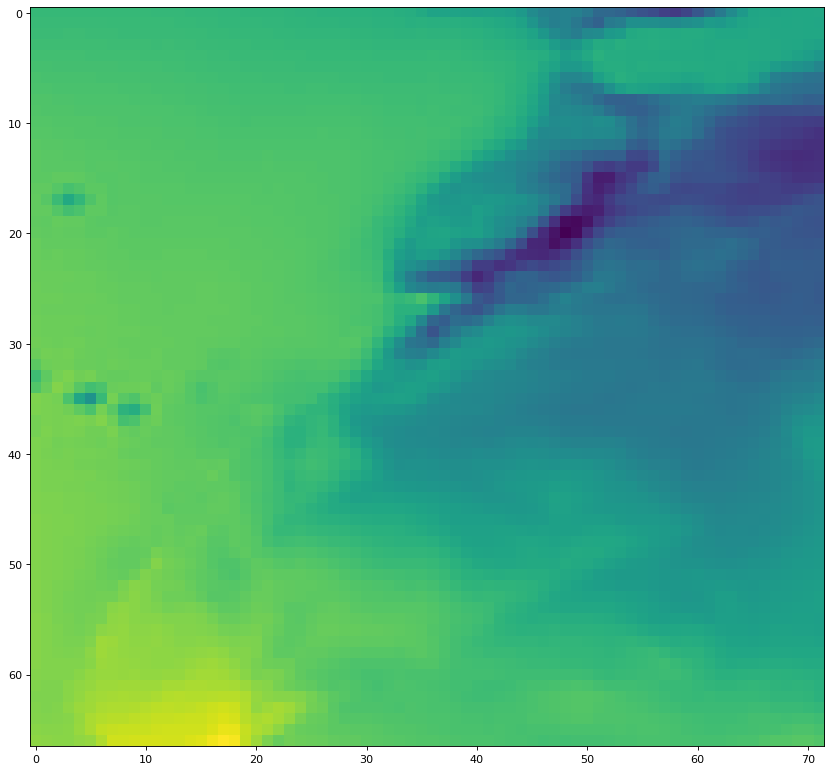

In [5]:
T = np.array(t[0])
T = np.reshape(T, (-1, 72))
print(T.shape)
plt.figure()
plt.figure(figsize=(14, 12), dpi=80)
plt.imshow(T)

In [23]:
P=[]
T=[]
for i in range(len(p)):
    P.append(np.reshape(p[i], (-1, 72)))
    T.append(np.reshape(t[i], (-1, 72)))

In [7]:
np.array(P).shape

(468, 67, 72)

In [98]:
np.array(P)

array([[[ 45.372795  ,  41.519978  ,  38.29852   , ...,   0.44463652,
           0.4018418 ,   0.18591481],
        [ 49.63984   ,  50.980606  ,  45.923573  , ...,   0.23405732,
           0.20454371,   0.        ],
        [ 59.84717   ,  50.288097  ,  55.925453  , ...,   1.0504601 ,
           1.318951  ,   1.0839175 ],
        ...,
        [ 29.33069   ,  22.557684  ,  16.58473   , ...,   0.        ,
           0.        ,   0.        ],
        [ 28.691475  ,  20.203323  ,  12.923151  , ...,   0.        ,
           0.        ,   0.        ],
        [ 25.304123  ,  19.603565  ,  13.218346  , ...,   0.        ,
           0.        ,   0.        ]],

       [[ 54.538227  ,  44.981575  ,  43.72963   , ...,  47.112488  ,
          51.510826  ,  52.56806   ],
        [ 53.65737   ,  53.98247   ,  47.985     , ...,  49.39296   ,
          56.34913   ,  51.870754  ],
        [ 65.71633   ,  54.52992   ,  52.664623  , ...,  48.180458  ,
          54.63025   ,  55.96705   ],
        ...,


In [8]:
lat=np.array(np.arange(20.5, 37.25, 0.25))
lat

array([20.5 , 20.75, 21.  , 21.25, 21.5 , 21.75, 22.  , 22.25, 22.5 ,
       22.75, 23.  , 23.25, 23.5 , 23.75, 24.  , 24.25, 24.5 , 24.75,
       25.  , 25.25, 25.5 , 25.75, 26.  , 26.25, 26.5 , 26.75, 27.  ,
       27.25, 27.5 , 27.75, 28.  , 28.25, 28.5 , 28.75, 29.  , 29.25,
       29.5 , 29.75, 30.  , 30.25, 30.5 , 30.75, 31.  , 31.25, 31.5 ,
       31.75, 32.  , 32.25, 32.5 , 32.75, 33.  , 33.25, 33.5 , 33.75,
       34.  , 34.25, 34.5 , 34.75, 35.  , 35.25, 35.5 , 35.75, 36.  ,
       36.25, 36.5 , 36.75, 37.  ])

In [9]:
np.arange(342.25, 360.25, 0.25)

lon=[]
j=-17.75
for i in range(72):
    lon.append(j + i*0.25)

np.array(lon)

array([-17.75, -17.5 , -17.25, -17.  , -16.75, -16.5 , -16.25, -16.  ,
       -15.75, -15.5 , -15.25, -15.  , -14.75, -14.5 , -14.25, -14.  ,
       -13.75, -13.5 , -13.25, -13.  , -12.75, -12.5 , -12.25, -12.  ,
       -11.75, -11.5 , -11.25, -11.  , -10.75, -10.5 , -10.25, -10.  ,
        -9.75,  -9.5 ,  -9.25,  -9.  ,  -8.75,  -8.5 ,  -8.25,  -8.  ,
        -7.75,  -7.5 ,  -7.25,  -7.  ,  -6.75,  -6.5 ,  -6.25,  -6.  ,
        -5.75,  -5.5 ,  -5.25,  -5.  ,  -4.75,  -4.5 ,  -4.25,  -4.  ,
        -3.75,  -3.5 ,  -3.25,  -3.  ,  -2.75,  -2.5 ,  -2.25,  -2.  ,
        -1.75,  -1.5 ,  -1.25,  -1.  ,  -0.75,  -0.5 ,  -0.25,   0.  ])

In [24]:
scipy.io.savemat('chirps_data_prep.mat', {'lat':np.arange(20.5, 37.25, 0.25).tolist()*72, 'precipitation':np.array(p), 'precipitation_units':np.array(['mm/month']), 'temperature':np.array(t), 'temperature_units':np.array(['Celsius'])})

In [42]:
mat = scipy.io.loadmat('PEthorn.mat')

In [39]:
mat

{'__header__': b'MATLAB 5.0 MAT-file, Platform: PCWIN64, Created on: Mon Apr 15 18:28:14 2024',
 '__version__': '1.0',
 '__globals__': [],
 'PE': array([[ 46.00794579,  45.94362381,  45.94270707, ...,  27.20059738,
          27.05305248,  25.84156114],
        [ 39.14000571,  39.17423936,  39.20018412, ...,  51.17098258,
          51.89740653,  50.32764415],
        [ 48.59362614,  48.71383826,  48.84536372, ..., 110.03326177,
         110.24106366, 107.82313224],
        ...,
        [ 89.54721384,  89.23949562,  88.86523163, ..., 168.392     ,
         168.392     , 168.392     ],
        [ 63.39734071,  62.94587637,  62.47303061, ..., 104.36002724,
         104.82613422, 103.1976185 ],
        [ 58.56093804,  58.06450057,  57.68933316, ...,  64.1263236 ,
          65.19224682,  64.04512463]])}

In [43]:
pdsi = pd.DataFrame(mat['PE'])
pdsi

,0,1,2,3,4,5,6,7,8,9,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,46.007946,45.943624,45.942707,46.074904,46.159606,46.262319,46.334510,46.160241,46.035603,45.913049,...,25.764083,25.833749,25.851062,25.937748,26.730772,27.098946,27.015714,27.200597,27.053052,25.841561
1,39.140006,39.174239,39.200184,39.075970,38.862036,38.685476,38.546365,38.497090,38.372752,38.203764,...,45.702029,46.119664,46.564667,46.310751,48.147790,49.756081,50.155495,51.170983,51.897407,50.327644
2,48.593626,48.713838,48.845364,48.964495,48.999783,49.017407,49.002201,48.940005,48.857475,48.838723,...,101.831028,102.979912,103.686069,102.789897,105.903341,108.033138,108.649261,110.033262,110.241064,107.823132
3,47.242303,47.261477,47.299788,47.454719,47.612851,47.745162,47.869030,47.845275,47.820791,47.811505,...,173.310000,173.310000,176.985000,176.008165,177.795000,179.076546,180.690906,181.500000,181.500000,178.200000
4,56.709793,56.658245,56.647506,56.775946,56.938693,57.123692,57.280968,57.287357,57.405662,57.563603,...,224.595000,225.860839,228.782117,227.463453,228.811000,228.811000,229.756500,230.702000,231.647500,232.593000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,105.717188,105.516206,105.281929,104.951854,104.645576,104.348788,104.100982,104.140747,104.224678,104.175764,...,219.356000,219.356000,219.356000,219.356000,222.952000,222.952000,223.432500,223.913000,224.393500,224.874000
464,96.877749,96.843704,96.806621,96.803066,96.814210,96.811128,96.830064,96.914375,96.808107,96.700965,...,188.490000,188.490000,188.490000,188.490000,188.490000,188.490000,188.490000,188.490000,188.490000,188.490000
465,89.547214,89.239496,88.865232,88.192377,87.342174,86.656193,86.113301,93.188766,100.249943,107.281205,...,162.378000,165.385000,165.385000,165.385000,166.441600,168.392000,168.392000,168.392000,168.392000,168.392000
466,63.397341,62.945876,62.473031,62.180232,61.734869,61.445405,61.320373,61.266278,61.301198,61.374200,...,92.305514,93.731416,95.575651,95.804976,98.984017,101.443775,102.597419,104.360027,104.826134,103.197619


In [44]:
pdsi.to_csv("outputchirps/PEthorn.csv")

**visualiseing output DI**

In [7]:
shp = pd.read_csv('shapefiles/01shp.csv', low_memory=False)
shp = shp.values.tolist()
shp = np.reshape(shp, (-1, 72))
index = pd.read_csv('output/CZI.csv', low_memory=False)
index = index.drop(['Unnamed: 0'], axis=1)
index = index.drop(['Dates'], axis=1)
index = index.values.tolist()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

(67, 72)


<Figure size 640x480 with 0 Axes>

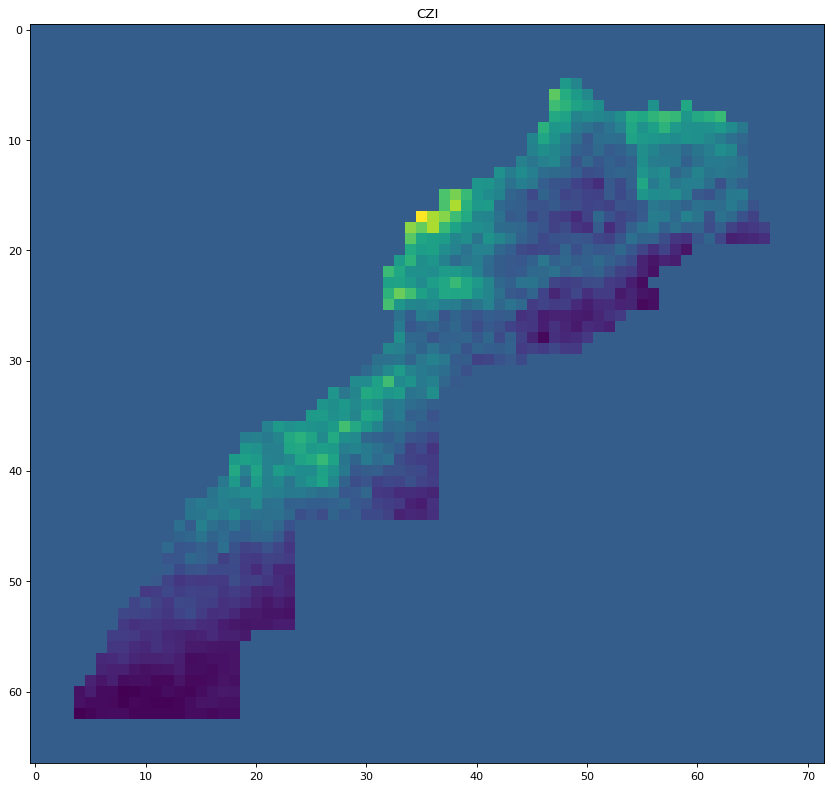

In [112]:
I = np.array(index[300])
I = np.reshape(I, (-1, 72))
print(I.shape)
plt.figure()
plt.figure(figsize=(14, 12), dpi=80)
plt.title('CZI')
plt.imshow(I*shp)

In [57]:
# export
driver = gdal.GetDriverByName("GTiff")
driver.Register()
outds = driver.Create("output/PDSI_300.tif", xsize = I.shape[1],
                      ysize = I.shape[0], bands = 1, 
                      eType = gdal.GDT_Float32)
#outds.SetGeoTransform(gt)
#outds.SetProjection(proj)
outband = outds.GetRasterBand(1)
outband.WriteArray(I)
outband.SetNoDataValue(np.nan)
outband.FlushCache()

# close your datasets and bands!!!
outband = None
outds = None

(60, 63)


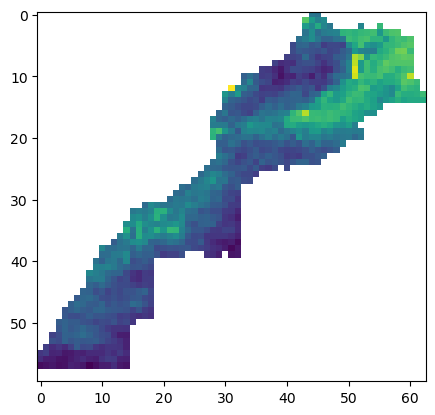

In [74]:
#Read and show TIF file
ds = gdal.Open(r"output/PDSI_300_clipped.tif")
gt= ds.GetGeoTransform()
proj= ds.GetProjection()

band = ds.GetRasterBand(1)                  
array = band.ReadAsArray().astype('float')
print(array.shape)
plt.figure() 
plt.imshow(array)

**ARC2 data**

In [2]:
arc = xr.open_dataset('D:\PhD\Datasets\ARC2\data.nc', decode_times=False)

c:\Users\ASchynO\anaconda3\lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated
  "class": algorithms.Blowfish,
c:\Users\ASchynO\anaconda3\lib\site-packages\xarray\backends\plugins.py:65: RuntimeWarning: Engine 'rasterio' loading failed:
DLL load failed while importing _base: The specified module could not be found.
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


In [4]:
arc

<xarray.Dataset>
Dimensions:   (T: 484, Y: 801, X: 751)
Coordinates:
  * T         (T) float32 276.5 277.5 278.5 279.5 ... 756.5 757.5 758.5 759.5
  * Y         (Y) float32 -40.0 -39.9 -39.8 -39.7 -39.6 ... 39.7 39.8 39.9 40.0
  * X         (X) float32 -20.0 -19.9 -19.8 -19.7 -19.6 ... 54.7 54.8 54.9 55.0
Data variables:
    est_prcp  (T, Y, X) float32 ...

In [3]:
arcp = arc.to_dataframe(['T', 'Y', 'X'])
arcp

est_prcp
T     Y     X                   
276.5 -40.0 -20.000000       NaN
            -19.900000       NaN
            -19.799999       NaN
            -19.700001       NaN
            -19.600000       NaN
...                          ...
759.5  40.0  54.599998  6.873966
             54.700001  6.505999
             54.799999  6.638216
             54.900002  6.926292
             55.000000  6.962708

[291150684 rows x 1 columns]

In [4]:
values = arcp['est_prcp'].to_list()

In [5]:
len(values)

291150684

In [6]:
#print(type(pdp.index.get_level_values("datetime")))
dates = arcp.index.get_level_values("T").to_numpy()
dates = list(dict.fromkeys(dates))
dates


[276.5,
 277.5,
 278.5,
 279.5,
 280.5,
 281.5,
 282.5,
 283.5,
 284.5,
 285.5,
 286.5,
 287.5,
 288.5,
 289.5,
 290.5,
 291.5,
 292.5,
 293.5,
 294.5,
 295.5,
 296.5,
 297.5,
 298.5,
 299.5,
 300.5,
 301.5,
 302.5,
 303.5,
 304.5,
 305.5,
 306.5,
 307.5,
 308.5,
 309.5,
 310.5,
 311.5,
 312.5,
 313.5,
 314.5,
 315.5,
 316.5,
 317.5,
 318.5,
 319.5,
 320.5,
 321.5,
 322.5,
 323.5,
 324.5,
 325.5,
 326.5,
 327.5,
 328.5,
 329.5,
 330.5,
 331.5,
 332.5,
 333.5,
 334.5,
 335.5,
 336.5,
 337.5,
 338.5,
 339.5,
 340.5,
 341.5,
 342.5,
 343.5,
 344.5,
 345.5,
 346.5,
 347.5,
 348.5,
 349.5,
 350.5,
 351.5,
 352.5,
 353.5,
 354.5,
 355.5,
 356.5,
 357.5,
 358.5,
 359.5,
 360.5,
 361.5,
 362.5,
 363.5,
 364.5,
 365.5,
 366.5,
 367.5,
 368.5,
 369.5,
 370.5,
 371.5,
 372.5,
 373.5,
 374.5,
 375.5,
 376.5,
 377.5,
 378.5,
 379.5,
 380.5,
 381.5,
 382.5,
 383.5,
 384.5,
 385.5,
 386.5,
 387.5,
 388.5,
 389.5,
 390.5,
 391.5,
 392.5,
 393.5,
 394.5,
 395.5,
 396.5,
 397.5,
 398.5,
 399.5,
 400.5,


In [7]:
lisp = [arcp.loc[d, 'est_prcp'].to_numpy() for d in dates]
lisp

[array([nan, nan, nan, ..., nan, nan, nan], dtype=float32),
 array([nan, nan, nan, ..., nan, nan, nan], dtype=float32),
 array([5.8222218 , 4.92381   , 4.857143  , ..., 0.05011486, 0.05142694,
        0.05242389], dtype=float32),
 array([nan, nan, nan, ..., nan, nan, nan], dtype=float32),
 array([10.299538, 10.041474, 10.149001, ...,  0.      ,  0.      ,
         0.      ], dtype=float32),
 array([nan, nan, nan, ..., nan, nan, nan], dtype=float32),
 array([nan, nan, nan, ..., nan, nan, nan], dtype=float32),
 array([3.9953914, 4.237327 , 4.4900146, ..., 0.       , 0.       ,
        0.       ], dtype=float32),
 array([5.7733984, 5.3596053, 5.628898 , ..., 0.       , 0.       ,
        0.       ], dtype=float32),
 array([5.735483 , 5.387557 , 5.9551454, ..., 0.       , 0.       ,
        0.       ], dtype=float32),
 array([nan, nan, nan, ..., nan, nan, nan], dtype=float32),
 array([2.       , 2.5092163, 2.5576031, ..., 0.       , 0.       ,
        0.       ], dtype=float32),
 array([0.

In [15]:
np.array(lisp).shape

(484, 601551)

In [8]:
stack = np.dstack(lisp)
stack

array([[[       nan,        nan, 5.8222218 , ..., 1.4642854 ,
         3.5483873 , 6.366666  ],
        [       nan,        nan, 4.92381   , ..., 1.1785711 ,
         3.8709671 , 6.        ],
        [       nan,        nan, 4.857143  , ..., 0.9642855 ,
         3.9999993 , 6.3333325 ],
        ...,
        [       nan,        nan, 0.05011486, ..., 0.22909454,
         1.5072184 , 6.6382165 ],
        [       nan,        nan, 0.05142694, ..., 0.23581278,
         1.6673151 , 6.9262924 ],
        [       nan,        nan, 0.05242389, ..., 0.24006663,
         1.4088515 , 6.962708  ]]], dtype=float32)

In [9]:
stack.shape

(1, 601551, 484)

In [10]:
def dataframe(p):

    df = pd.DataFrame({'Dates': dates, 'precip': stack[0][p]})
    df.set_index("Dates", inplace = True)
    return df

In [13]:
dataframe(200)

,precip
Dates,
276.5,NaN
277.5,NaN
278.5,0.733333
279.5,NaN
280.5,8.986177
...,...
755.5,0.000000
756.5,0.435484
757.5,0.696428


**CHIRPS25 data**

In [14]:
##1_imports
import os
import glob
import fiona

##2_WorkSpace// Input Files
os.chdir('C:/Users/Oubaha.ANAS/Workspace/Datasets/CHIRPS2')

# Create an output folder for the clipped TIFF files
output_folder = "Resamples"
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# Directory of TIFF files (from workspace)
CHIRPSFiles = glob.glob('*.tif')

# Loop over TIFF files
for f in CHIRPSFiles:
    
    #ds = gdal.Open(f)

    # Define the new file name for the clipped TIFF
    new_file_name = os.path.join(output_folder, f"{os.path.splitext(f)[0]}.tif")

    #Resample data from 0.05 to 0.25 degrees
    gdal.Warp(new_file_name, f, xRes=0.25, yRes=0.25, srcNodata=-9999, dstNodata=0, resampleAlg='average')
    


In [15]:
import glob
#get Soil Moisture files
CHIRPSFiles = glob.glob('C:/Users/Oubaha.ANAS/Workspace/Datasets/CHIRPS2/Resamples/*.tif')
# get the value of Soil Moistur in each file
lis1=[]
for f in CHIRPSFiles:
    SM = gdal.Open(f)                    
    Band = SM.GetRasterBand(1)                  
    Data = Band.ReadAsArray().astype('float')
    lis1.append(Data)

In [16]:
print(len(lis1))
lis1[0]

468


array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

(67, 72)


<Figure size 640x480 with 0 Axes>

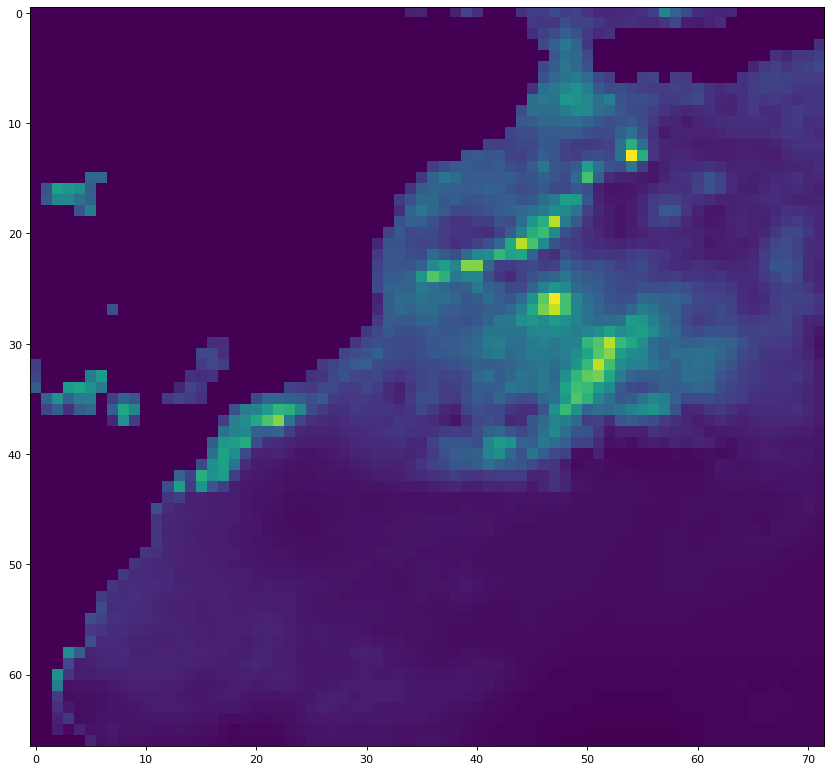

In [17]:
clip = lis1[0][52:119, 649:721]
print(clip.shape)
plt.figure()
plt.figure(figsize=(14, 12), dpi=80)
plt.imshow(clip)#lis1[0][260:590, 3245:3600]

In [18]:
lisp = [np.array(lis1[i][52:119, 649:721]).flatten() for i in range(468)]
lisp

[array([0.        , 0.        , 0.        , ..., 0.91090381, 0.87413836,
        0.80285692]),
 array([0.        , 0.        , 0.        , ..., 0.3195436 , 0.30078349,
        0.20800073]),
 array([0.        , 0.        , 0.        , ..., 0.55802667, 0.55407757,
        0.63158673]),
 array([0.        , 0.        , 0.        , ..., 0.2078124 , 0.22540592,
        0.21416828]),
 array([0.        , 0.        , 0.        , ..., 1.52183044, 1.64107955,
        1.6440748 ]),
 array([0.        , 0.        , 0.        , ..., 0.61628747, 1.21969485,
        3.20171237]),
 array([0.        , 0.        , 0.        , ..., 4.73715448, 5.72247076,
        7.72929811]),
 array([ 0.        ,  0.        ,  0.        , ..., 12.64111137,
        14.0008707 , 20.17273521]),
 array([0.        , 0.        , 0.        , ..., 7.87445259, 7.9064908 ,
        9.79411316]),
 array([0.        , 0.        , 0.        , ..., 0.7627582 , 0.70177501,
        0.58487433]),
 array([0.        , 0.        , 0.        , 

In [22]:
p = pd.read_csv('C:/Users/Oubaha.ANAS/Workspace/Code/Article1-MeteoIndices/precip_pixels.csv', low_memory=False)
p = p[:-8]
p

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,45.372795,41.519978,38.298520,33.130142,33.649406,43.004400,37.958540,46.379086,40.360332,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,01-02-83,54.538227,44.981575,43.729630,38.954320,39.524376,43.692974,46.819496,46.842700,39.810715,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,01-03-83,43.373627,48.152634,47.043810,59.528854,51.707195,43.105110,41.883816,40.159250,38.529602,...,0.510164,0.706140,0.417943,0.000000,0.000000,0.220665,0.197361,0.209387,0.246599,0.389134
3,01-04-83,55.761684,54.913590,69.151980,59.632690,64.048240,53.445170,56.921368,59.128273,54.414690,...,0.267766,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,01-05-83,35.753826,41.820335,36.096573,33.503025,39.073950,33.861347,29.803953,41.040310,27.788918,...,0.000000,0.000000,0.180426,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,22.811615,29.206140,13.051861,16.098978,20.791270,39.569350,38.950558,19.518747,22.631813,...,15.260876,14.936295,10.755119,14.499843,23.112558,23.491543,31.898220,31.842310,32.929690,25.700810
464,01-09-21,21.961075,20.171535,22.197544,28.227942,33.186726,30.554653,35.399230,26.070858,27.464762,...,1.841476,1.512185,0.978490,1.609783,3.345638,2.930855,3.004042,2.672900,2.345905,1.780274
465,01-10-21,13.248849,16.825666,14.905464,15.792293,14.234770,14.943135,10.031117,10.310531,7.308455,...,1.168269,0.755937,0.671670,0.508833,0.921345,1.191549,0.765403,0.654625,0.909648,0.302581
466,01-11-21,6.978646,9.362622,6.738851,8.530106,6.208407,9.736192,8.518650,12.832383,14.366604,...,1.039282,1.104646,0.822026,0.747268,0.464146,0.416986,0.322446,0.368270,0.430918,0.459465


In [19]:
stack = np.dstack(lisp)
stack

array([[[0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        ...,
        [0.91090381, 0.3195436 , 0.55802667, ..., 0.80112606,
         0.29267979, 0.18141191],
        [0.87413836, 0.30078349, 0.55407757, ..., 0.73474962,
         0.25360194, 0.13836351],
        [0.80285692, 0.20800073, 0.63158673, ..., 0.57697576,
         0.26894519, 0.17203167]]])

In [23]:
def dataframe(pixel):
    df = pd.DataFrame({'Dates': p["Dates"], 'precip': stack[0][pixel]})
    df.set_index("Dates", inplace = True)
    return df

In [24]:
dataframe(4823)

,precip
Dates,
01-01-83,0.802857
01-02-83,0.208001
01-03-83,0.631587
01-04-83,0.214168
01-05-83,1.644075
...,...
01-08-21,19.034260
01-09-21,5.486821
01-10-21,0.576976


In [25]:
frames = [dataframe(p) for p in range(0, 4824)]

In [26]:
df = pd.concat(frames,axis=1)
df.columns = [str(i) for i in range(4824)]
df

,0,1,2,3,4,5,6,7,8,9,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
Dates,,,,,,,,,,,,,,,,,,,,,
01-01-83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.835147,0.892011,0.913272,0.980090,0.993104,0.962703,0.943237,0.910904,0.874138,0.802857
01-02-83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.938125,0.889869,0.842389,0.648331,0.510979,0.395234,0.354732,0.319544,0.300783,0.208001
01-03-83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.723936,0.563924,0.468948,0.424501,0.490576,0.518140,0.527819,0.558027,0.554078,0.631587
01-04-83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.323204,0.414349,0.512259,0.576357,0.536608,0.386123,0.258037,0.207812,0.225406,0.214168
01-05-83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.537330,1.879496,1.731603,1.360364,1.222028,1.179074,1.366379,1.521830,1.641080,1.644075
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
01-08-21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,29.597576,26.494379,22.541325,21.605145,22.691751,26.692093,29.359907,27.457743,20.756685,19.034260
01-09-21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,10.471135,9.113500,8.790627,7.191433,7.105859,7.724066,5.275350,3.953682,5.029363,5.486821
01-10-21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.138719,1.072318,1.052535,1.067817,1.083172,1.142860,0.967633,0.801126,0.734750,0.576976


In [28]:
#df.to_csv("C:/Users/Oubaha.ANAS/Workspace/Code/Article1-MeteoIndices/precip_chirps.csv")
df.to_excel('C:/Users/Oubaha.ANAS/Workspace/Code/Article1-MeteoIndices/precip_chirps.xlsx', index=True)

**Fails**

In [51]:
import fiona
t= xr.open_dataset('C:/Users/Oubaha.ANAS/Workspace/Datasets/ERA5/ERA5-83-22.nc')
t

<xarray.Dataset>
Dimensions:    (longitude: 73, latitude: 68, time: 480)
Coordinates:
  * longitude  (longitude) float32 -18.0 -17.75 -17.5 -17.25 ... -0.5 -0.25 0.0
  * latitude   (latitude) float32 37.0 36.75 36.5 36.25 ... 20.75 20.5 20.25
  * time       (time) datetime64[ns] 1983-01-01 1983-02-01 ... 2022-12-01
Data variables:
    t2m        (time, latitude, longitude) float32 ...
Attributes:
    Conventions:  CF-1.6
    history:      2023-12-25 08:43:02 GMT by grib_to_netcdf-2.25.1: /opt/ecmw...

In [60]:
geodf = gpd.read_file("C:/Users/Oubaha.ANAS/Workspace/Code/Article1-MeteoIndices/shapfiles/Morocco/Morocco.shp")
xds = rioxarray.open_rasterio('C:/Users/Oubaha.ANAS/Workspace/Datasets/ERA5/ERA5-83-22.nc')
xds = xds.rio.write_crs(geodf.crs)
clipped = xds.rio.clip(geodf.geometry.apply(mapping), geodf.crs, all_touched= True)
clipped.to_netcdf('C:/Users/Oubaha.ANAS/Workspace/Datasets/ERA5/ERA5-83-22-clipped.nc')

In [61]:
clipped

<xarray.DataArray 't2m' (time: 480, y: 62, x: 65)>
array([[[-32767, -32767, -32767, ..., -32767, -32767, -32767],
        [-32767, -32767, -32767, ..., -32767, -32767, -32767],
        [-32767, -32767, -32767, ..., -32767, -32767, -32767],
        ...,
        [   186,    727,   1042, ..., -32767, -32767, -32767],
        [  -197, -32767, -32767, ..., -32767, -32767, -32767],
        [   -75, -32767, -32767, ..., -32767, -32767, -32767]],

       [[-32767, -32767, -32767, ..., -32767, -32767, -32767],
        [-32767, -32767, -32767, ..., -32767, -32767, -32767],
        [-32767, -32767, -32767, ..., -32767, -32767, -32767],
        ...,
        [  2049,   3398,   4072, ..., -32767, -32767, -32767],
        [  1025, -32767, -32767, ..., -32767, -32767, -32767],
        [   943, -32767, -32767, ..., -32767, -32767, -32767]],

       [[-32767, -32767, -32767, ..., -32767, -32767, -32767],
        [-32767, -32767, -32767, ..., -32767, -32767, -32767],
        [-32767, -32767, -32767, ..., -32767, -32767, -32767],
        ...,
...
        [  7806,  11051,  12791, ..., -32767, -32767, -32767],
        [  7100, -32767, -32767, ..., -32767, -32767, -32767],
        [  6635, -32767, -32767, ..., -32767, -32767, -32767]],

       [[-32767, -32767, -32767, ..., -32767, -32767, -32767],
        [-32767, -32767, -32767, ..., -32767, -32767, -32767],
        [-32767, -32767, -32767, ..., -32767, -32767, -32767],
        ...,
        [  5876,   7906,   8952, ..., -32767, -32767, -32767],
        [  5511, -32767, -32767, ..., -32767, -32767, -32767],
        [  5562, -32767, -32767, ..., -32767, -32767, -32767]],

       [[-32767, -32767, -32767, ..., -32767, -32767, -32767],
        [-32767, -32767, -32767, ..., -32767, -32767, -32767],
        [-32767, -32767, -32767, ..., -32767, -32767, -32767],
        ...,
        [  2930,   4007,   4750, ..., -32767, -32767, -32767],
        [  2783, -32767, -32767, ..., -32767, -32767, -32767],
        [  2862, -32767, -32767, ..., -32767, -32767, -32767]]],
      dtype=int16)
Coordinates:
  * y            (y) float64 36.0 35.75 35.5 35.25 ... 21.5 21.25 21.0 20.75
  * x            (x) float64 -17.0 -16.75 -16.5 -16.25 ... -1.75 -1.5 -1.25 -1.0
  * time         (time) object 1983-01-01 00:00:00 ... 2022-12-01 00:00:00
    spatial_ref  int32 0
Attributes:
    latitude#long_name:      latitude
    latitude#units:          degrees_north
    longitude#long_name:     longitude
    longitude#units:         degrees_east
    Conventions:             CF-1.6
    history:                 2023-12-25 08:43:02 GMT by grib_to_netcdf-2.25.1...
    NETCDF_DIM_EXTRA:        {time}
    NETCDF_DIM_time_DEF:     [480.   4.]
    NETCDF_DIM_time_VALUES:  [ 727560.  728304.  728976.  729720.  730440.  7...
    add_offset:              291.5421359046027
    long_name:               2 metre temperature
    scale_factor:            0.0006891282946187417
    units:                   ('K', 'K', 'K', 'K', 'K', 'K', 'K', 'K', 'K', 'K...
    _FillValue:              -32767

In [41]:
##1_imports
import os
import glob
import fiona

##2_WorkSpace// Input Files
os.chdir('C:/Users/Oubaha.ANAS/Workspace/Datasets/CHIRPS2')

# Read Shape file
with fiona.open("C:/Users/Oubaha.ANAS/Workspace/Code/Article1-MeteoIndices/shapfiles/Morocco/Morocco.shp", "r") as shapefile:
    shapes = [feature["geometry"] for feature in shapefile]

# Create an output folder for the clipped TIFF files
output_folder = "clippedResamples"
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# Directory of TIFF files (from workspace)
CHIRPSFiles = glob.glob('*.tif')

# Loop over TIFF files
for f in CHIRPSFiles:

    #Resample data from 0.05 to 0.25 degrees
    gdal.Warp('output.tiff', f, xRes=0.25, yRes=0.25, srcNodata=-9999, dstNodata=0, resampleAlg='sum')#

    # read imagery file
    with rasterio.open('output.tiff') as src:
        out_image, out_transform = rasterio.mask.mask(src, shapes, crop=True)
        out_meta = src.meta
        #src.close() # close the rasterio dataset

    # Save clipped imagery
    out_meta.update({"driver": "GTiff",
                    "height": out_image.shape[1],
                    "width": out_image.shape[2],
                    "transform": out_transform})
    
    # Define the new file name for the clipped TIFF
    new_file_name = os.path.join(output_folder, f"{os.path.splitext(f)[0]}.tif")

    with rasterio.open(new_file_name, "w", **out_meta) as dest:
        dest.write(out_image)
        #dest.close()
    
    #remove output file
    #os.remove('output.tif')


In [113]:
def resize(array, nrows, ncols):
    array[array < 0] = 0
    r, h = array.shape
    newarr = (array.reshape(h//nrows, nrows, -1, ncols)
                 .swapaxes(1, 2)
                 .reshape(-1, nrows, ncols))
    sumarr = [i.mean() for i in newarr]
    return np.reshape(sumarr,(-1, np.int16(h/ncols)))


In [67]:
arr = np.array([[1,1,1,1,1,1,1,1,1,1],
                [2,2,2,2,2,2,2,2,2,2],
                [3,3,3,3,3,3,3,3,3,3],
                [4,4,4,4,4,4,4,4,4,4],
                [5,5,5,5,5,5,5,5,5,5],
                [6,6,6,6,6,6,6,6,6,6],
                [7,7,7,7,7,7,7,7,7,7],
                [8,8,8,8,8,8,8,8,8,8],
                [9,9,9,9,9,9,9,9,9,9],
                [0,0,0,0,0,0,0,0,0,0],])
#newarr = resize(arr, 2, 2)
#newarr

array([[3, 3, 3],
       [4, 4, 4]])

In [112]:
newclip

array([[-3.99508017e+03, -3.99387621e+03, -4.79488227e+03, ...,
        -7.99790618e+03, -7.99716731e+03, -5.99593941e+03],
       [-5.99560385e+03, -5.99624463e+03, -5.99638886e+03, ...,
        -9.99900000e+03, -9.99900000e+03, -9.99900000e+03],
       [-9.99900000e+03, -9.99900000e+03, -9.99900000e+03, ...,
        -9.99900000e+03, -9.99900000e+03, -9.99900000e+03],
       ...,
       [ 1.80693352e+00, -1.99811197e+03, -1.99798396e+03, ...,
         1.13511058e+00,  1.00195950e+00,  9.17281537e-01],
       [ 8.45159205e-01,  7.72907869e-01,  7.43695263e-01, ...,
         2.66560833e+00,  2.55589748e+00,  2.55823633e+00],
       [ 2.58220224e+00,  2.48731867e+00,  2.45623524e+00, ...,
        -1.99791098e+03, -1.99822080e+03, -1.99828615e+03]])

(66, 71)


<Figure size 640x480 with 0 Axes>

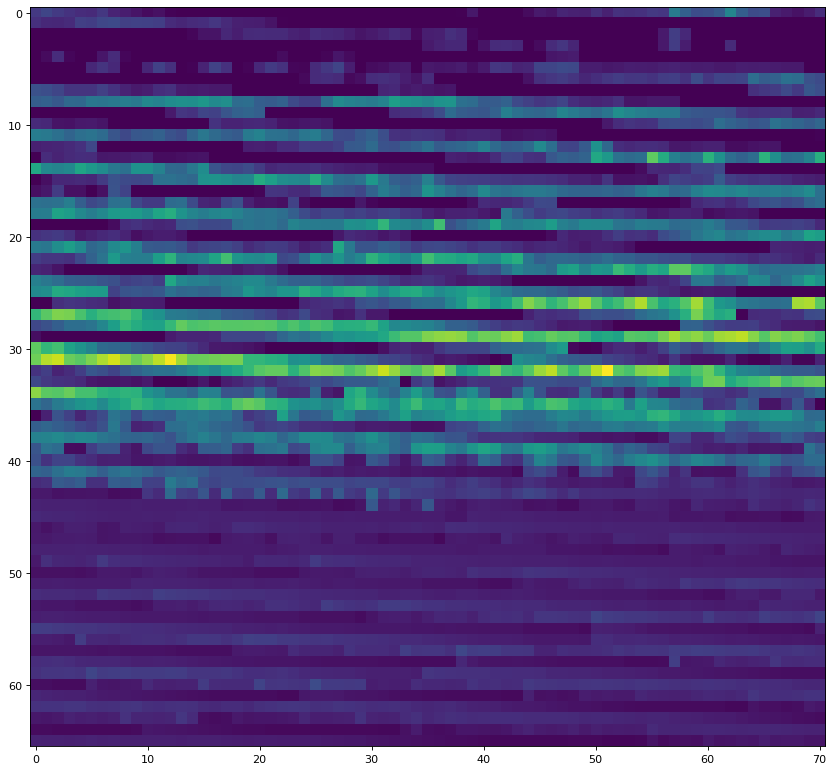

In [115]:
newclip = resize(clip, 5, 5)
print(newclip.shape)
plt.figure()
plt.figure(figsize=(14, 12), dpi=80)
plt.imshow(newclip)#lis1[0][260:590, 3245:3600]

In [8]:
v = gdal.Open('C:/Users/Oubaha.ANAS/Workspace/Code/Article2-Tracking/output/shp_clip.tif')                    
Band = v.GetRasterBand(1)                  
Data = Band.ReadAsArray().astype('float')
Data = Data.flatten()
Data

array([nan, nan, nan, ..., nan, nan, nan])

In [18]:
res = []
[res.append(x) for x in Data if x not in res and np.isnan(x) == False ]
res

[0.0]

In [19]:
count = 0
for i in Data:
    if i == 0: count+=1

count 

1016